# 1. Explore the data

Synthea synthetic EHR export: patients, encounters and the events recorded at each encounter.
Goal of the project: at each encounter, predict which workflows the patient will need in the
**next 30 days** — medical exam, lab test, imaging, instrument test.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.data import encounter_frame, load_raw
from workflow_ml.labels import build_labels, workflow_events

raw = load_raw()
pd.Series({name: len(frame) for name, frame in raw.items()}, name="rows").to_frame()

,rows
patients,1171
encounters,53346
conditions,8376
medications,42989
careplans,3483
procedures,34981
observations,299697
imaging_studies,855
immunizations,15478


## Encounters per patient
A few patients have more than 1,500 encounters. They matter later, when we evaluate.

,count,mean,std,min,25%,50%,75%,max
encounters per patient,1171.0,45.6,97.7,2.0,16.0,27.0,54.0,2006.0


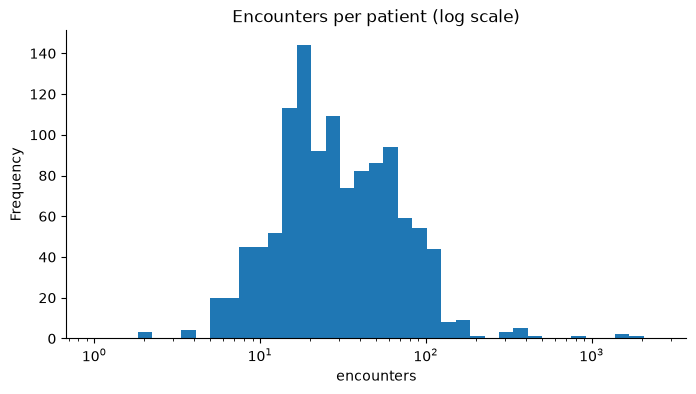

In [3]:
index = encounter_frame(raw)
per_patient = index.groupby("patient_id").size()
per_patient.plot.hist(bins=np.logspace(0, 3.4, 40), logx=True, title="Encounters per patient (log scale)")
plt.xlabel("encounters")
per_patient.describe().round(1).to_frame("encounters per patient").T

## Labels
A label is 1 when an event of that category is recorded strictly after the encounter and within 30 days.

,medical_exam,lab_test,imaging,instrument_test
positive rate,0.173,0.182,0.018,0.043


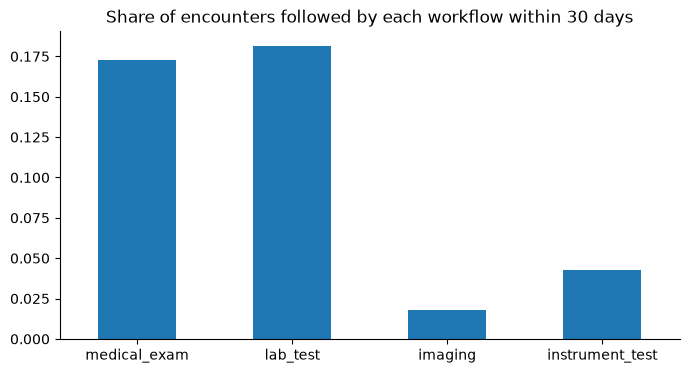

In [4]:
labels = build_labels(index, workflow_events(raw))
labels.mean().plot.bar(title="Share of encounters followed by each workflow within 30 days", rot=0)
labels.mean().round(3).to_frame("positive rate").T

In [5]:
labels.groupby(index["enc_class"]).mean().round(3)

,medical_exam,lab_test,imaging,instrument_test
enc_class,,,,
ambulatory,0.261,0.324,0.025,0.065
emergency,0.229,0.172,0.021,0.070
inpatient,0.195,0.186,0.082,0.016
outpatient,0.182,0.116,0.013,0.034
urgentcare,0.563,0.564,0.029,0.202
wellness,0.025,0.025,0.005,0.005


## Visits follow schedules
Wellness visits repeat about every 371 days. Features that measure *time since the last visit of a kind* can therefore predict the next one.

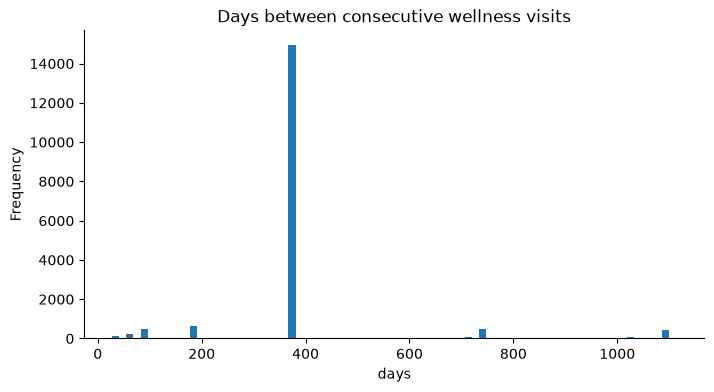

In [6]:
wellness = index[index["enc_class"] == "wellness"]
gaps = wellness.groupby("patient_id")["t"].diff().dt.days.dropna()
gaps[gaps < 1200].plot.hist(bins=80, title="Days between consecutive wellness visits")
plt.xlabel("days");